# EDA

In [ ]:
import pandas as pd

df = pd.read_csv('./data/regression_bonus_practice_data.csv')
df.head()


In [ ]:
df['final_test'].isnull().head()

In [ ]:
df.info()


In [ ]:
df.describe()

In [ ]:
df.isnull().sum()

In [ ]:
int(df.duplicated().sum())

# Data Preparation

## Data Cleaning

### Filling empty cells

In [ ]:
# CCA is a categorical column so we take null CCA as not having any CCA
df['CCA'] = df['CCA'].fillna(value="None")
# Since final_test is the label, we need to drop rows with missing labels
df.dropna(subset=['final_test'], inplace=True)
# Attendance has missing numerical values so the mean value is used for fillna
df['attendance_rate'] = df['attendance_rate'].fillna(df['attendance_rate'].mean(numeric_only=True))
# Check 
df.isnull().sum()

### Checking for mislabelled data within categorical columns

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


Plotting 12 columns: ['number_of_siblings', 'direct_admission', 'CCA', 'learning_style', 'gender', 'tuition', 'age', 'sleep_time', 'wake_time', 'mode_of_transport', 'bag_color', 'sleeping_hours']


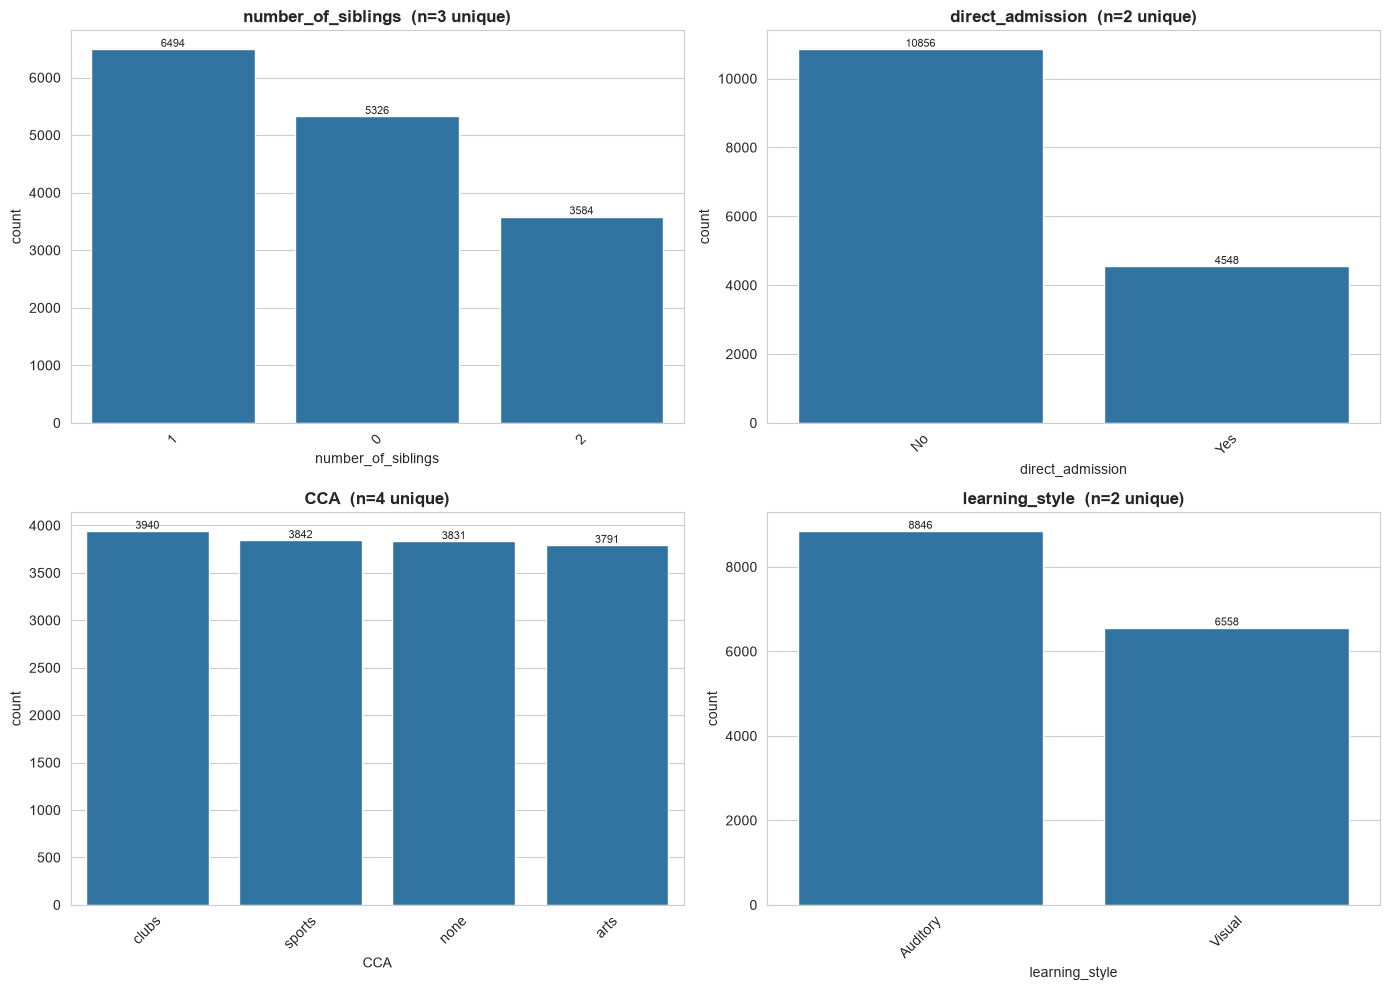

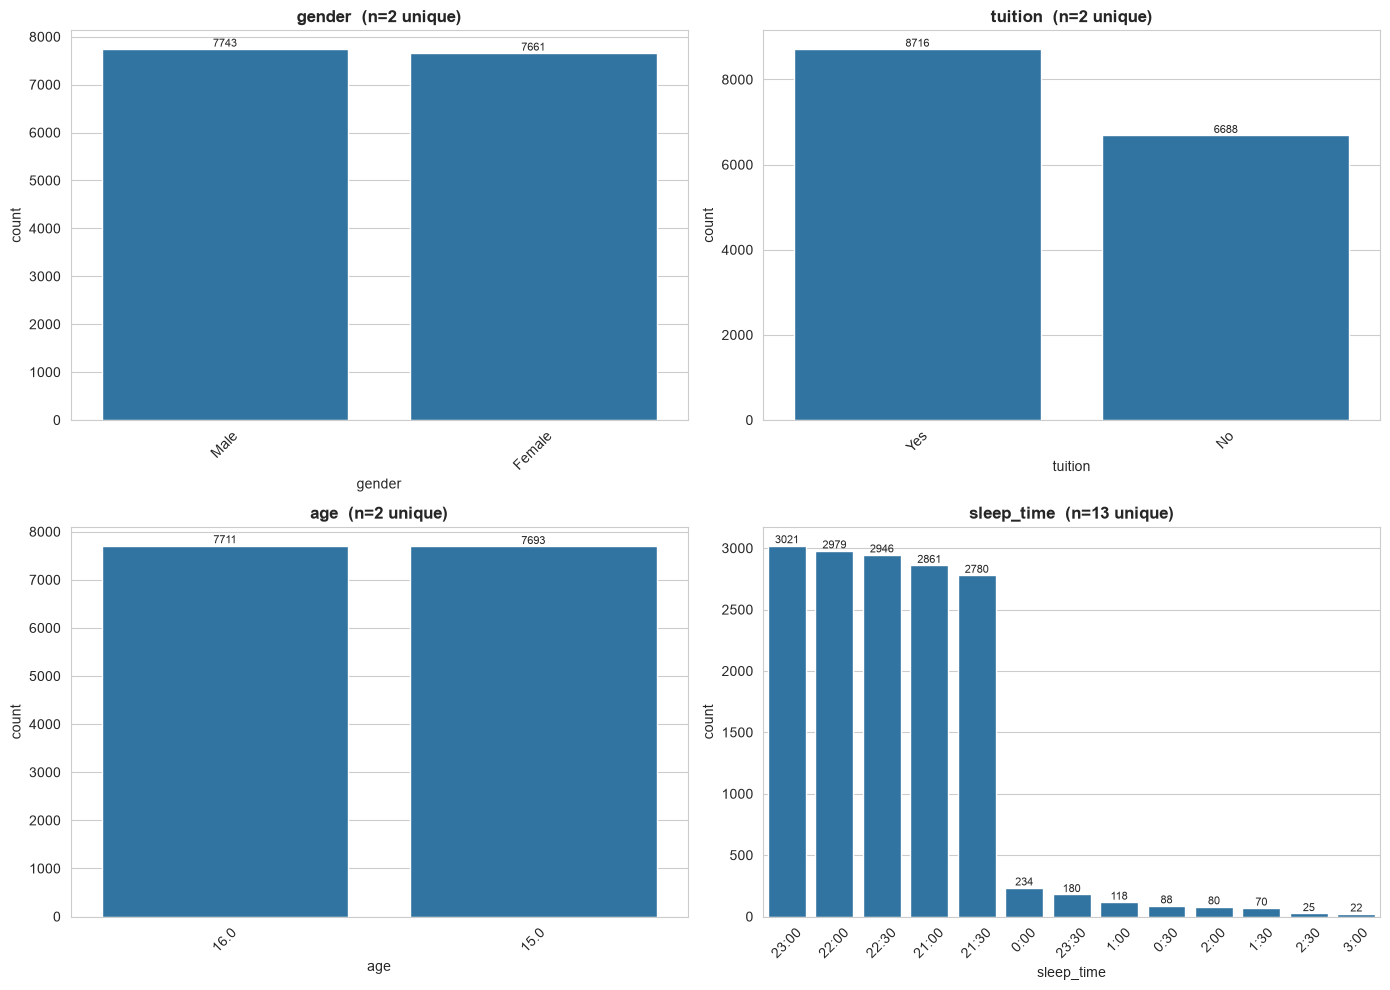

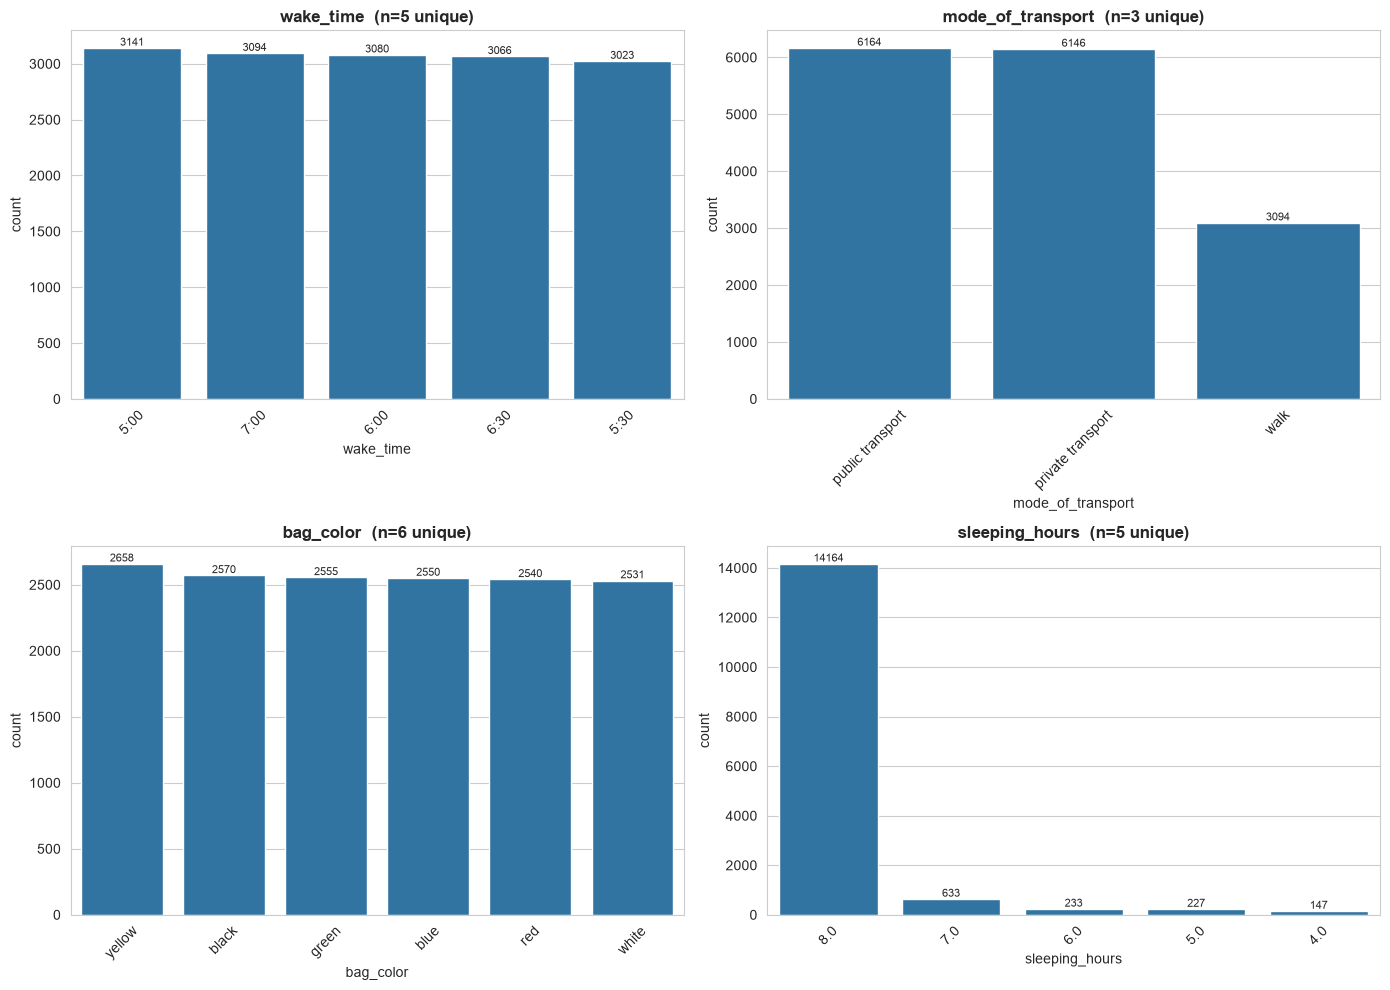

In [53]:

sns.set_style("whitegrid")

MAX_CATEGORIES = 20   # skip / trim columns with more unique values than this

cat_cols = df.columns.tolist()

# Drop columns that are too high-cardinality to be useful as bar charts
cat_cols = [c for c in cat_cols if df[c].nunique() <= MAX_CATEGORIES]

print(f"Plotting {len(cat_cols)} columns: {cat_cols}")

BATCH_SIZE = 4          # 2 per row x 2 rows per figure
n_per_row = 2

for start in range(0, len(cat_cols), BATCH_SIZE):
    batch = cat_cols[start:start + BATCH_SIZE]
    n_rows = math.ceil(len(batch) / n_per_row)

    fig, axes = plt.subplots(n_rows, n_per_row, figsize=(14, 5 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(batch):
        ax = axes[i]
        order = df[col].value_counts().index          # sorted by frequency
        sns.countplot(x=col, data=df, ax=ax, order=order)
        ax.set_title(f'{col}  (n={df[col].nunique()} unique)', fontsize=12, fontweight='bold')
        ax.tick_params(axis='x', rotation=45)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f'{int(h)}',
                            (p.get_x() + p.get_width()/2., h),
                            ha='center', va='bottom', fontsize=8)

    for j in range(len(batch), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()
    plt.close(fig)      # <- frees memory, prevents accumulation

**From the bar chart output, there are several columns with mislabelled data. In the tuition column there are entries with "Y" and "N" that should be labelled "Yes" and "No". In the age column there are 5 entries with negative values**
**that should be removed and students with ages 5 and 6 that should not be taking O levels. In the CCA column there are entries with fully capitalised names of the CCA labels they represent.**

### Standardising Categorical Labels

In [ ]:
# Replace "Y" and "N" to "Yes" and "No" in 'tuition' column
df ['tuition'] = df['tuition'].replace('Y', 'Yes')
df ['tuition'] = df['tuition'].replace('N', 'No')

# Assuming the ages 5 and 6 were meant to be data collected as ages 15 and 16 (Appropriate age for taking O levels), ages 5 and 6 will be replaced with 15 and 16 respectively. Assuming -5 was an supposed to represent 15, it is also replaced with 15. 
# However the single entry with age -4 is regarded as an outlier and can be removed without significant impact on the data
df['age'] = df['age'].replace(5, 15)
df['age'] = df['age'].replace(6, 16)
df['age'] = df['age'].replace(-5, 15)
df= df[df['age'] != -4]

# Replace labels in column CCA with fully uncapitalised letters to avoid misclassification
df['CCA'] = df['CCA'].str.lower()


### Feature Engineering

**Combining sleep_time and wake_time features into a singular feature "sleeping_hours" which is more representative of how the class label might be influenced**

In [52]:
import numpy as np
# 1. Clean the time strings by adding seconds ':00' so pandas reads them as HH:MM:SS
wake = pd.to_timedelta(df['wake_time'] + ':00')
sleep = pd.to_timedelta(df['sleep_time'] + ':00')

# 2. Subtract wake time from sleep time (wake_time - sleep_time)
delta = wake - sleep

# 3. Handle the midnight wrap-around (e.g., sleeping at 22:00, waking at 6:00)
delta = np.where(delta < pd.Timedelta(0), delta + pd.Timedelta(days=1), delta)

# 4. Overwrite the column with the correct fractional hours
df['sleeping_hours'] = delta.astype(int) / 3600000000


print(df.tail())

       index  number_of_siblings direct_admission     CCA learning_style  \
15895  15895                   1               No   clubs         Visual   
15896  15896                   1              Yes    none       Auditory   
15897  15897                   1              Yes  sports       Auditory   
15898  15898                   1               No   clubs         Visual   
15899  15899                   2              Yes    none         Visual   

      student_id  gender tuition  final_test  n_male  n_female   age  \
15895     XPECN2  Female      No        56.0    12.0      14.0  16.0   
15896     7AMC7S    Male     Yes        85.0    17.0       5.0  16.0   
15897     XKZ6VN  Female     Yes        76.0     7.0      10.0  15.0   
15898     2OU4UQ    Male     Yes        45.0    18.0      12.0  16.0   
15899     D9OKLV    Male      No        87.0    11.0       7.0  16.0   

       hours_per_week  attendance_rate sleep_time wake_time  \
15895             9.0             96.0      22:

In [59]:
# Now that sleeping_hours is engineered as a feature drawing data from sleep_time and wake_time, these 2 features can be removed from the dataset
# Index, student_id are irrelevant features that do not contribute meaningful information to the dataset and can be dropped as well
df.drop(columns=['sleep_time', 'wake_time', 'index', 'student_id'])

,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,mode_of_transport,bag_color,sleeping_hours
0,0,Yes,sports,Visual,Female,No,69.0,14.0,2.0,16.0,10.0,91.00000,private transport,yellow,8.0
1,2,No,sports,Auditory,Female,No,47.0,4.0,19.0,16.0,7.0,94.00000,private transport,green,8.0
2,0,Yes,none,Visual,Male,No,85.0,14.0,2.0,15.0,8.0,92.00000,private transport,white,8.0
3,1,No,clubs,Auditory,Female,Yes,64.0,2.0,20.0,15.0,18.0,93.26577,public transport,yellow,8.0
4,0,No,sports,Auditory,Male,No,66.0,24.0,3.0,16.0,7.0,95.00000,public transport,yellow,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15895,1,No,clubs,Visual,Female,No,56.0,12.0,14.0,16.0,9.0,96.00000,private transport,black,8.0
15896,1,Yes,none,Auditory,Male,Yes,85.0,17.0,5.0,16.0,7.0,91.00000,private transport,white,8.0
15897,1,Yes,sports,Auditory,Female,Yes,76.0,7.0,10.0,15.0,7.0,93.00000,walk,red,8.0
15898,1,No,clubs,Visual,Male,Yes,45.0,18.0,12.0,16.0,3.0,94.00000,walk,yellow,8.0
